# Homework
## Problems [Part 1](./01_Linear-Algebra.md)

1. Consider the following pistons connected in series. You want to find
   the distance each piston moves when equal and opposite forces are
   applied to each side. In case 1, you consider the motion of all five
   pistons, but in case 2 you set the motion of piston 5 to 0. 

![Springs-masses](../images/series-springs_01-02.png)

Using a FBD for each piston, in case 1:

$k_1x_{1}-k_2x_{2}=F$

$(k_1 +k_2)x_2 -k_1x_1 - k_2x_3 = 0$

$(k_2 +k_3)x_3 -k_2x_2 - k_3x_4 = 0$

$(k_3 +k_4)x_4 -k_3x_3 - k_4x_5 = 0$

$k_4x_5 - k_4x_4 = -F$

in matrix form:

$\left[ \begin{array}{ccccc}
k_1 & -k_1 & 0 & 0 & 0\\
-k_1 & k_1+k_2 & -k_2 & 0 & 0 \\
0 & -k_2 & k_2+k_3 & -k_3 & 0\\
0 & 0 & -k_3 & k_3+k_4 & -k_4\\
0 & 0 & 0 & -k_4 & k_4  
\end{array} \right]
\left[ \begin{array}{c}
x_{1} \\
x_{2} \\
x_{3} \\
x_{4} \\
x_{5}\end{array} \right]=
\left[ \begin{array}{c}
F \\
0 \\
0 \\
0 \\
-F \end{array} \right]$

Try to use `np.linalg.solve` to find the piston x-positions. Do you get
any warnings or errors? _use stiffness values of $k_* = 1$ and force of
$F=1$

In [1]:
import numpy as np

k = 1
F = 1
A = k * np.array([
    [1, -1, 0, 0, 0],
    [-1, 2, -1, 0, 0],
    [0, -1, 2, -1, 0],
    [0, 0, -1, 2, -1],
    [0, 0, 0, -1, 1],
])
b = np.array([F, 0, 0, 0, -F])

try:
    x = np.linalg.solve(A, b)
    print(x)
except np.linalg.LinAlgError as error:
    print('LinAlgError:', error)

print(f'Condition number: {np.linalg.cond(A):.3e}')

LinAlgError: Singular matrix
Condition number: 2.128e+16


Now, consider case 2, 

Using a FBD for each piston, in case 2:

$k_1x_{1}-k_2x_{2}=F$

$(k_1 +k_2)x_2 -k_1x_1 - k_2x_3 = 0$

$(k_2 +k_3)x_3 -k_2x_2 - k_3x_4 = 0$

$(k_3 +k_4)x_4 -k_3x_3 = 0$

in matrix form:

$\left[ \begin{array}{cccc}
k_1 & -k_1 & 0 & 0 \\
-k_1 & k_1+k_2 & -k_2 & 0 \\
0 & -k_2 & k_2+k_3 & -k_3 \\
0 & 0 & -k_3 & k_3+k_4 \\
\end{array} \right]
\left[ \begin{array}{c}
x_{1} \\
x_{2} \\
x_{3} \\
x_{4} \end{array} \right]=
\left[ \begin{array}{c}
F \\
0 \\
0 \\
0 \end{array} \right]$

Try to use `np.linalg.solve` to find the piston x-positions. Do you get
any warnings or errors? Why does this solution work better [hint: check
condition
numbers](./01_Linear-Algebra.md#Singular-and-ill-conditioned-matrices)

In [2]:
A2 = k * np.array([
    [1, -1, 0, 0],
    [-1, 2, -1, 0],
    [0, -1, 2, -1],
    [0, 0, -1, 2],
])
b2 = np.array([F, 0, 0, 0])
x2 = np.linalg.solve(A2, b2)

print('[x1, x2, x3, x4, x5] =', np.append(x2, 0))
print(f'Condition number: {np.linalg.cond(A2):.2f}')

[x1, x2, x3, x4, x5] = [4. 3. 2. 1. 0.]
Condition number: 29.28


With all five pistons free, the rows of $A$ sum to zero. Moving all the pistons by the same distance leaves every spring stretch unchanged. That is why `np.linalg.solve` reports a singular matrix and why the computed condition number is so large.

Fixing $x_5=0$ gives a reference position. The reduced system has a condition number of about 29.28 and gives $(4,3,2,1,0)$ without a warning or error.

![HVAC diagram showing the flow rates and connections between floors](../images/hvac.png)

2. In the figure above you have an idealized Heating, Ventilation and
   Air conditioning (HVAC) system. In the current configuration, the
   three-room building is being cooled off by $T_{in}$ air fed into the
   building at $\dot{m}_1. Our goal is to determine the steady-state temperatures of the rooms given the following information

* $\dot{m}_1=0.1~kg/s$
* $\dot{m}_2=0.12~kg/s$
* $\dot{m}_3=0.12~kg/s$
* $\dot{m}_4=0.1~kg/s$
* $\dot{m}_5=0.02~kg/s$
* $\dot{m}_6=0.02~kg/s$
* $C_p=1000~\frac{J}{kg-K}$
* $\dot{Q}_{in} = 300~W$
* $T_{in} = 12^{o} C$

The energy-balance equations for rooms 1-3 create three equations:

1. $\dot{m}_1 C_p T_{in}+\dot{Q}_{in}-\dot{m}_2 C_p T_{1}+\dot{m}_6 C_p T_{2} = 0$

2. $\dot{m}_2 C_p T_{1}+\dot{Q}_{in}+\dot{m}_5 C_p T_{3}-\dot{m}_3 C_p T_{2}-\dot{m}_6 C_p T_{2} = 0$

3. $\dot{m}_3 C_p T_{2}+\dot{Q}_{in}-\dot{m}_5 C_p T_{3}-\dot{m}_4 C_p T_{3} = 0$

Identify the unknown variables and constants to create a linear algebra problem in the form of $\mathbf{Ax}=\mathbf{b}$.

a. Create the matrix $\mathbf{A}$

b. Create the known vector $\mathbf{b}$

c. Solve for the unknown variables, $\mathbf{x}$

d. What are the warmest and coldest rooms? What are their temperatures?

In [3]:
m1, m2, m3, m4, m5, m6 = 0.1, 0.12, 0.12, 0.1, 0.02, 0.02
Cp, Tin, Q = 1000, 12, 300

A = Cp * np.array([
    [-m2, m6, 0],
    [m2, -m3-m6, m5],
    [0, m3, -m4-m5],
])
b = np.array([-m1*Cp*Tin-Q, -Q, -Q])
x = np.linalg.solve(A, b)

print('A =\n', A)
print('b =', b)
print('T1 = {:.2f} °C, T2 = {:.2f} °C, T3 = {:.2f} °C'.format(*x))

A =
 [[-120.   20.    0.]
 [ 120. -140.   20.]
 [   0.  120. -120.]]
b = [-1500.  -300.  -300.]
T1 = 15.58 °C, T2 = 18.50 °C, T3 = 21.00 °C


The unknowns are $T_1$, $T_2$, and $T_3$. Keeping the temperature terms on the left and moving the known inputs to the right gives

$$
\begin{aligned}
-120T_1+20T_2 &= -1500,\\
120T_1-140T_2+20T_3 &= -300,\\
120T_2-120T_3 &= -300.
\end{aligned}
$$

Room 1 is the coldest at **15.58 °C** and room 3 is the warmest at **21.00 °C**.

3. The [Hilbert Matrix](https://en.wikipedia.org/wiki/Hilbert_matrix) has a high condition number and as the matrix increases dimensions, the condition number increases. Find the condition number of a 

a. $1 \times 1$ Hilbert matrix

b. $5 \times 5$ Hilbert matrix

c. $10 \times 10$ Hilbert matrix

d. $15 \times 15$ Hilbert matrix

e. $20 \times 20$ Hilbert matrix

If the accuracy of each matrix element is $\approx 10^{-16}$, what is the expected rounding error in the solution $\mathbf{Ax} = \mathbf{b}$, where $\mathbf{A}$ is the Hilbert matrix.

In [4]:
for n in [1, 5, 10, 15, 20]:
    H = np.array([[1/(i+j+1) for j in range(n)] for i in range(n)])
    cond = np.linalg.cond(H)
    print(f'{n:2d}x{n}: condition = {cond:.3e}, relative error scale = {cond*1e-16:.3e}')

 1x1: condition = 1.000e+00, relative error scale = 1.000e-16
 5x5: condition = 4.766e+05, relative error scale = 4.766e-11
10x10: condition = 1.602e+13, relative error scale = 1.602e-03
15x15: condition = 8.718e+17, relative error scale = 8.718e+01
20x20: condition = 1.033e+19, relative error scale = 1.033e+03


The notes estimate the relative rounding-error scale as $\mathrm{cond}(H)\times10^{-16}$. It reaches about $0.16\%$ for the $10\times10$ matrix. For both larger sizes the estimate exceeds 1, so there are no guaranteed accurate digits.

## Problems [Part 2](./02_Gauss_elimination.md)

1. 4 masses are connected in series to 4 springs with K=100N/m. What are the final positions of the masses? 

![Springs-masses](../images/mass_springs.png)

The masses haves the following amounts, 1, 2, 3, and 4 kg for masses 1-4. Using a FBD for each mass:

$m_{1}g+k(x_{2}-x_{1})-kx_{1}=0$

$m_{2}g+k(x_{3}-x_{2})-k(x_{2}-x_{1})=0$

$m_{3}g+k(x_{4}-x_{3})-k(x_{3}-x_{2})=0$

$m_{4}g-k(x_{4}-x_{3})=0$

in matrix form K=100 N/m:

$\left[ \begin{array}{cccc}
2k & -k & 0 & 0 \\
-k & 2k & -k & 0 \\
0 & -k & 2k & -k \\
0 & 0 & -k & k \end{array} \right]
\left[ \begin{array}{c}
x_{1} \\
x_{2} \\
x_{3} \\
x_{4} \end{array} \right]=
\left[ \begin{array}{c}
m_{1}g \\
m_{2}g \\
m_{3}g \\
m_{4}g \end{array} \right]$

In [5]:
def GaussNaive(A, b):
    n = len(b)
    Aug = np.column_stack((A, b)).astype(float)

    # Forward elimination
    for k in range(n - 1):
        for i in range(k + 1, n):
            factor = Aug[i, k] / Aug[k, k]
            Aug[i, :] -= factor * Aug[k, :]

    # Back substitution
    x = np.zeros(n)
    for k in range(n - 1, -1, -1):
        x[k] = (Aug[k, -1] - Aug[k, k+1:n] @ x[k+1:n]) / Aug[k, k]
    return x, Aug


k = 100
g = 9.81
A = k * np.array([
    [2, -1, 0, 0],
    [-1, 2, -1, 0],
    [0, -1, 2, -1],
    [0, 0, -1, 1],
])
b = g * np.array([1, 2, 3, 4])
x, Aug = GaussNaive(A, b)

print('[U | y] =\n', Aug.round(3))
print('[x1, x2, x3, x4] =', x.round(4), 'm downward')

[U | y] =
 [[ 200.    -100.       0.       0.       9.81 ]
 [   0.     150.    -100.       0.      24.525]
 [   0.       0.     133.333 -100.      45.78 ]
 [   0.       0.       0.      25.      73.575]]
[x1, x2, x3, x4] = [0.981  1.8639 2.5506 2.943 ] m downward


![Triangular truss](../images/truss.png)

For problems __2-3__, consider the simple 3-element triangular truss, shown above, with a point load applied at the tip. The goal is to understand what tension is in the horizontal element, $P_1$. In problem __2__, the applied force is verical $(\theta=0)$ and in problem __3__ the applied force varies in angle $(\theta \neq 0)$. 

2. In the truss shown above, calculate the tension in bar 1, $P_1$, when $\theta=0$. When $\theta=0$, the $\sum F=0$ at each corner creates 3 equations and 3 unknowns as such (here, you reduce the number of equations with symmetry, $P_2=P_3,~R_2=R_3,~and~R_1=0$ ). 

$\left[ \begin{array}{ccc}
1 & \cos\alpha & 0 \\
0 & 2\sin\alpha & 0 \\
0 & -\sin\alpha &  1 \\
 \end{array} \right]
\left[ \begin{array}{c}
P_{1} \\
P_{2} \\
R_{2} \end{array} \right]=
\left[ \begin{array}{c}
0 \\
F \\
0 \end{array} \right]$

a. Create the system of equations, $\mathbf{Ax}=\mathbf{b}$, when $\alpha=75^o$, $\beta=30^o$, and $F=1~kN$. Use __Gauss elimination__ to solve for $P_1,~P_2,~and~R_2$. What is the resulting augmented matrix, $\mathbf{A|y}$ after Gauss elimination?

b. Solve for the $\mathbf{LU}$ decomposition of $\mathbf{A}$. 

c. Use the $\mathbf{LU}$ solution to solve for the tension in bar 1 $(P_1)$ every 10 N values of force, F, between 100 N and 1100 N. Plot $P_1~vs~F$.

[U | y] =
 [[1.       0.258819 0.       0.      ]
 [0.       1.931852 0.       1.      ]
 [0.       0.       1.       0.5     ]]
[P1, P2, R2] (kN) = [-0.133975  0.517638  0.5     ]
L =
 [[ 1.   0.   0. ]
 [ 0.   1.   0. ]
 [ 0.  -0.5  1. ]]
U =
 [[1.       0.258819 0.      ]
 [0.       1.931852 0.      ]
 [0.       0.       1.      ]]


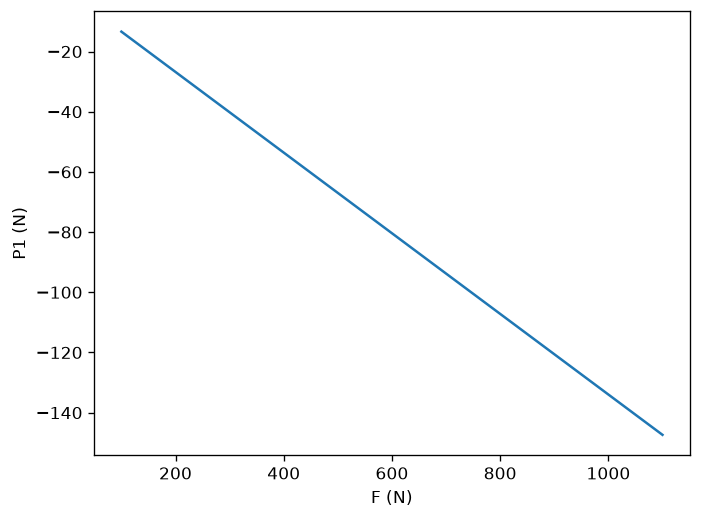

In [6]:
import matplotlib.pyplot as plt

# a. Gaussian elimination
alpha = np.deg2rad(75)
s, c = np.sin(alpha), np.cos(alpha)
A = np.array([
    [1, c, 0],
    [0, 2*s, 0],
    [0, -s, 1],
])
b = np.array([0, 1, 0])  # F = 1 kN
x, Aug = GaussNaive(A, b)
print('[U | y] =\n', Aug.round(6))
print('[P1, P2, R2] (kN) =', x.round(6))

# b. Save the elimination factors in L
def LUNaive(A):
    n = len(A)
    L = np.eye(n)
    U = A.astype(float)
    for k in range(n - 1):
        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]
            U[i, :] -= L[i, k] * U[k, :]
    return L, U


L, U = LUNaive(A)
print('L =\n', L.round(6))
print('U =\n', U.round(6))

# c. Reuse L and U as F changes
def solveLU(L, U, b):
    n = len(b)
    y = np.zeros(n)
    x = np.zeros(n)
    for k in range(n):
        y[k] = b[k] - L[k, :k] @ y[:k]
    for k in range(n - 1, -1, -1):
        x[k] = (y[k] - U[k, k+1:] @ x[k+1:]) / U[k, k]
    return x


F = np.arange(100, 1101, 10)
P1 = np.zeros(len(F))
for i in range(len(F)):
    P1[i] = solveLU(L, U, np.array([0, F[i], 0]))[0]

plt.figure()
plt.plot(F, P1)
plt.xlabel('F (N)')
plt.ylabel('P1 (N)')
plt.show()

The only nonzero elimination factor below the diagonal is $L_{32}=(-\sin\alpha)/(2\sin\alpha)=-1/2$. Subtracting $-1/2$ times row 2 from row 3 gives the upper triangular matrix. The supplied equations give $P_1\approx-0.133975F$.

3. Using the same truss as shown above, let's calculate the tension in bar 1, $P_1$, when $\theta=[0...90^o]$ and $F=[100...1100]~kN$. When $\theta\neq 0$, the resulting 6 equations and 6 unknowns are given in the following matrix

$\left[ \begin{array}{ccc}
0 & \sin\alpha & 0 & 1 & 0 & 0 \\
1 & \cos\alpha & 0 & 0 & 1 & 0 \\
0 & \cos\beta/2 & \cos\beta/2 & 0 & 0 & 0 \\
0 & -\sin\beta/2 & \sin\beta/2 & 0 & 0 & 0 \\
-1 & 0 & \cos\alpha & 0 & 0 & 0 \\
0 & 0 & \sin\alpha & 0 & 0 & 1 \\
 \end{array} \right]
\left[ \begin{array}{c}
P_{1} \\
P_{2} \\
P_{3} \\
R_{1} \\
R_{2} \\
R_{3}\end{array} \right]=
\left[ \begin{array}{c}
0 \\
0 \\
F\cos\theta \\
-F\sin\theta \\
0 \\
0 \end{array} \right]$

a. Create the system of equations, $\mathbf{Ax}=\mathbf{b}$, when $\alpha=75^o$, $\beta=30^o$, $\theta=45^o=\pi/4$, and $F=1~kN$. Use __Gauss elimination__ to solve for $P_1,~P_2,~P_3,~R_1,~R_2,~and~R_3$. What is the resulting augmented matrix, $\mathbf{A|y}$ after Gauss elimination? _Hint: do you see a problem with the order of the equations? How can you __pivot__ to fix it?_

b. Solve for the $\mathbf{PLU}$ decomposition of $\mathbf{A}$. 

c. Use the $\mathbf{PLU}$ solution to solve for the tension in bar 1 $(P_1)$ every 10 N values of force, F, between 100 N and 1100 N. Plot $P_1~vs~F$.

[U | y] =
 [[ 1.        0.258819  0.        0.        1.        0.        0.      ]
 [ 0.        0.965926  0.        1.        0.        0.        0.      ]
 [ 0.        0.        0.965926 -1.        0.        0.        0.707107]
 [ 0.        0.        0.        0.535898  0.        0.       -0.896575]
 [ 0.        0.        0.        0.        1.        0.       -0.189469]
 [ 0.        0.        0.        0.        0.        1.        0.965926]]
[P1, P2, P3, R1, R2, R3] (kN) = [-0.258819  1.732051 -1.       -1.673033 -0.189469  0.965926]
P =
 [[0 1 0 0 0 0]
 [1 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 0 0 0 1]]
L =
 [[ 1.        0.        0.        0.        0.        0.      ]
 [ 0.        1.        0.        0.        0.        0.      ]
 [ 0.        1.        1.        0.        0.        0.      ]
 [ 0.       -0.267949  0.267949  1.        0.        0.      ]
 [-1.        0.267949  0.267949  0.        1.        0.      ]
 [ 0.        0.        1.        1.86602

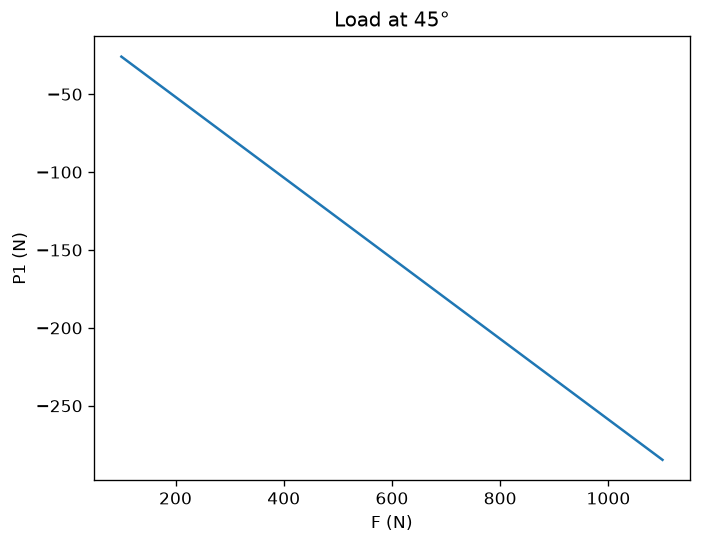

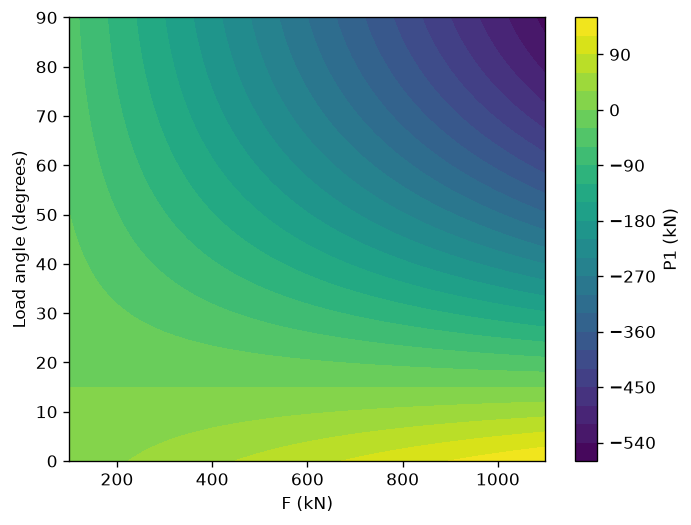

In [7]:
# a. Swap rows 1 and 2 before elimination
alpha, beta, theta = np.deg2rad([75, 30, 45])
s, c = np.sin(alpha), np.cos(alpha)
sb, cb = np.sin(beta/2), np.cos(beta/2)
A = np.array([
    [0, s, 0, 1, 0, 0],
    [1, c, 0, 0, 1, 0],
    [0, cb, cb, 0, 0, 0],
    [0, -sb, sb, 0, 0, 0],
    [-1, 0, c, 0, 0, 0],
    [0, 0, s, 0, 0, 1],
])
b = np.array([0, 0, np.cos(theta), -np.sin(theta), 0, 0])  # F = 1 kN
rows = [1, 0, 2, 3, 4, 5]
x, Aug = GaussNaive(A[rows], b[rows])
print('[U | y] =\n', Aug.round(6))
print('[P1, P2, P3, R1, R2, R3] (kN) =', x.round(6))

# b. P.T @ A = L @ U, so A = P @ L @ U
P = np.eye(len(b), dtype=int)[:, rows]
L, U = LUNaive(P.T @ A)
print('P =\n', P)
print('L =\n', L.round(6))
print('U =\n', U.round(6))

# c. Vary F at 45 degrees
F = np.arange(100, 1101, 10)
P1 = np.zeros(len(F))
for i in range(len(F)):
    P1[i] = solveLU(L, U, P.T @ (F[i]*b))[0]

plt.figure()
plt.plot(F, P1)
plt.xlabel('F (N)')
plt.ylabel('P1 (N)')
plt.title('Load at 45°')
plt.show()

# Force and angle sweep from the introduction
F_kN = np.arange(100, 1101, 10)
angles = np.arange(91)
P1 = np.zeros((len(angles), len(F_kN)))
for i, angle in enumerate(np.deg2rad(angles)):
    b_unit = np.array([0, 0, np.cos(angle), -np.sin(angle), 0, 0])
    P1[i, :] = solveLU(L, U, P.T @ b_unit)[0] * F_kN

plt.figure()
plt.contourf(F_kN, angles, P1, levels=25)
plt.xlabel('F (kN)')
plt.ylabel('Load angle (degrees)')
plt.colorbar(label='P1 (kN)')
plt.show()

The first diagonal entry is zero, so I swapped rows 1 and 2 in both $A$ and $b$ before calling `GaussNaive`. That swap gives a nonzero pivot in every column during elimination. The same permutation gives $P^TA=LU$, and the force sweep uses `solveLU(L, U, P.T @ b)`.

Part (c) uses $\theta=45^\circ$ and 100–1100 N. The angle sweep uses 100–1100 kN as stated in the introduction. The two supplied truss matrices use different signs for the horizontal equilibrium terms and give opposite signs for $P_1$ at $\theta=0$.

## Problems [Part 3](./03_Linear-regression-algebra.md)

<img
src="https://i.imgur.com/LoBbHaM.png" alt="prony series diagram"
style="width: 300px;"/> <img src="https://i.imgur.com/8i140Zu.png" alt
= "stress relax data" style="width: 400px;"/> 

Viscoelastic Prony series model and stress-vs-time relaxation curve of wheat kernels [[3]](https://www.cerealsgrains.org/publications/plexus/cfw/pastissues/2013/Documents/CFW-58-3-0139.pdf). Stress relaxation curve of a wheat kernel from regressed equation data that illustrate where to locate relaxation times (vertical dotted lines) and stresses (horizontal black marks). $\sigma$ = stress; t = time.

2. [Viscoelasticity](https://en.wikipedia.org/wiki/Viscoelasticity) is a property of materials that exhibit stiffness, but also tend to flow slowly. One example is [Silly Putty](https://en.wikipedia.org/wiki/Silly_Putty), when you throw a lump it bounces, but if you leave it on a table it _creeps_, slowly flowing downwards. In the stress-vs-time plot above, a wheat kernel was placed under constant strain and the stress was recorded. In a purely elastic material, the stress would be constant. In a purely viscous material, the stress would decay to 0 MPa. 

Here, you have a viscoelastic material, so there is some residual elastic stress as $t\rightarrow \infty$. The researchers used a 4-part [Prony series](https://en.wikipedia.org/wiki/Prony%27s_method) to model viscoelasticity. The function they fit was

$\sigma(t) = a_1 e^{-t/1.78}+a_2 e^{-t/11}+a_3e^{-t/53}+a_4e^{-t/411}+a_5$

a. Load the data from the graph shown above in the file `../data/stress_relax.dat`. 

b. Create a $\mathbf{Z}$-matrix to perform the least-squares regression for the given Prony series equation $\mathbf{y} = \mathbf{Za}$.

c. Solve for the constants, $a_1,~a_2,~a_3,~a_4~,a_5$

d. Plot the best-fit function and the data from `../data/stress_relax.dat` _Use at least 50 points in time to get a smooth best-fit line._

[a1, a2, a3, a4, a5] (MPa) = [ 1.901753  3.273737  1.059689  2.27847  30.554056]


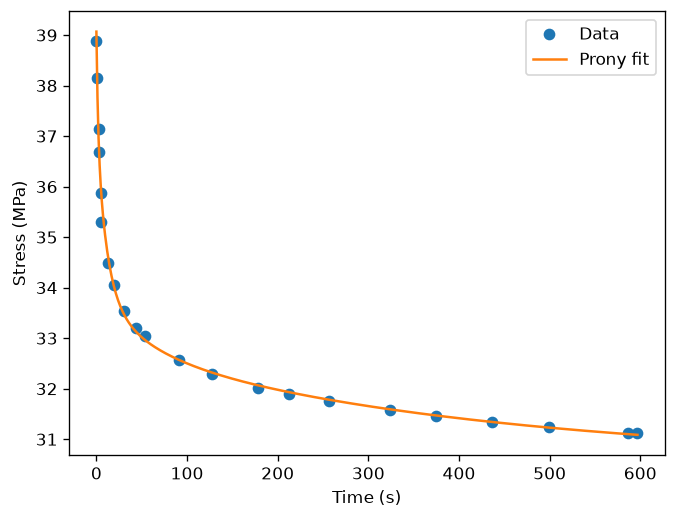

In [8]:
# a. Load time and stress
stress_data = np.loadtxt('../data/stress_relax.dat', delimiter=',', skiprows=1)
t = stress_data[:, 0]
y = stress_data[:, 1]

# b and c. Build Z and solve the normal equations
Z = np.block([
    [np.exp(-t/1.78)], [np.exp(-t/11)], [np.exp(-t/53)], [np.exp(-t/411)], [t**0],
]).T
a = np.linalg.solve(Z.T @ Z, Z.T @ y)
print('[a1, a2, a3, a4, a5] (MPa) =', a.round(6))

# d. Evaluate the fit on a finer time grid
t_fit = np.linspace(min(t), max(t), 500)
Z_fit = np.block([
    [np.exp(-t_fit/1.78)], [np.exp(-t_fit/11)], [np.exp(-t_fit/53)],
    [np.exp(-t_fit/411)], [t_fit**0],
]).T
plt.figure()
plt.plot(t, y, 'o', label='Data')
plt.plot(t_fit, Z_fit @ a, label='Prony fit')
plt.xlabel('Time (s)')
plt.ylabel('Stress (MPa)')
plt.legend()
plt.show()

3. Load the '../data/primary-energy-consumption-by-region.csv' that has the energy consumption of different regions of the world from 1965 until 2018 [Our world in Data](https://ourworldindata.org/energy). 
You are going to compare the energy consumption of the United States to all of Europe. Load the data into a pandas dataframe. *Note: you can get certain rows of the data frame by specifying what you're looking for e.g. 
`EUR = dataframe[dataframe['Entity']=='Europe']` will give us all the rows from Europe's energy consumption.*

a. Use a piecewise least-squares regression to find a function for the energy consumption as a function of year

energy consumed = $f(t) = At+B+C(t-1970)H(t-1970)$

c. What is your prediction for US energy use in 2025? How about European energy use in 2025?

In [9]:
import pandas as pd

data = pd.read_csv('../data/primary-energy-consumption-by-region.csv')
for region in ['United States', 'Europe']:
    region_data = data[data['Entity'] == region]
    t = region_data['Year'].values
    y = region_data['Primary Energy Consumption (terawatt-hours)'].values

    # a. Piecewise fit
    Z = np.block([[t], [t**0], [(t-1970)*(t>=1970)]]).T
    fit = np.linalg.solve(Z.T @ Z, Z.T @ y)
    print('{}: A = {:.4f}, B = {:.4f}, C = {:.4f}'.format(region, *fit))

    # c. Evaluate at 2025
    t_pred = 2025
    Z_pred = np.array([t_pred, 1, (t_pred-1970)*(t_pred>=1970)])
    print(f'2025: {Z_pred @ fit:,.2f} TWh')

United States: A = 923.0483, B = -1799475.4487, C = -744.0634
2025: 28,773.82 TWh
Europe: A = 1506.1581, B = -2948659.2282, C = -1345.2518
2025: 27,322.11 TWh


As in the temperature-anomaly example, the third column of $Z$ is $(t-1970)(t\geq1970)$. The slope is $A$ before 1970 and $A+C$ afterward. The 2025 extrapolations are **28,773.82 TWh** for the United States and **27,322.11 TWh** for Europe.